# Лабораторная работа №2: Визуализация и разведочный анализ данных (EDA)
**Дисциплина**: Основы искусственного интеллекта (ОИИ 26/27)  
**Учебное заведение**: ГОУ «ПГУ им. Т.Г. Шевченко», Физико-технический институт  
**Кафедра**: Информационных технологий  
**Студент**: Гандапас Даниил Владимирович  
**Группа**: ФТ24ДР62ПИ1  
**Вариант**: №2  
**База данных**: Northwind_large.sqlite  

---
### Задания Варианта №2:
1. **Barplot**: Столбчатая диаграмма средней выручки по категориям товаров.
2. **Histogram + Density plot**: Гистограмма и график плотности (KDE) для количества товаров в одном заказе.
3. **Pie chart**: Круговая диаграмма по уровням скидки (на три группы для $0 < \text{Discount}$).
4. **Scatter plot + Trend**: Диаграмма зависимости выручки заказа от месяца оформления с добавлением линии линейного тренда.
5. **Heatmap**: Тепловая карта количества заказов по городам и месяцам.


## 0. Инициализация окружения и подготовка базы данных
При выполнении в **Google Colab** блок автоматически скачает проверенную полноразмерную базу `Northwind_large.sqlite` напрямую с GitHub репозитория и проверит её целостность.


In [1]:
import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка единого стиля графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 11

DB_FILE = 'Northwind_large.sqlite'
DB_URL = 'https://raw.githubusercontent.com/Asm-o-Dan/eli5-visual-hub/main/downloads/Northwind_large.sqlite'
EXPECTED_SIZE = 32235520

if not os.path.exists(DB_FILE) and os.path.exists(os.path.join('labs', 'oii_lab1', DB_FILE)):
    DB_FILE = os.path.join('labs', 'oii_lab1', DB_FILE)

# Автоскачивание при запуске в Google Colab
if not os.path.exists(DB_FILE) or os.path.getsize(DB_FILE) < EXPECTED_SIZE:
    print(f"Загрузка базы данных {DB_FILE} с GitHub...")
    import urllib.request
    urllib.request.urlretrieve(DB_URL, DB_FILE)
    print(f"База успешно загружена. Размер: {os.path.getsize(DB_FILE)} байт.")

conn = sqlite3.connect(DB_FILE)
print("Успешное подключение к SQLite базе данных!")


Успешное подключение к SQLite базе данных!


---
## Задание 1. Столбчатая диаграмма средней выручки по категориям товаров (Barplot)

### Зачем этот график?
Позволяет сравнить доходность товарных категорий: мы выявляем, какие категории формируют наиболее высокий средний чек по одной позиции, а какие относятся к сегменту недорогих массовых товаров.

### Формула и логика:
- Выручка одной позиции с учетом скидки: `UnitPrice * Quantity * (1 - Discount)`.
- Рассчитывается средняя выручка (`AVG`) для каждой товарной категории через объединение таблиц `OrderDetail`, `Product` и `Category`.


CategoryName,AvgItemRevenue,TotalRevenue,PositionsCount
Meat/Poultry,1378.26,66907617.83,48545
Beverages,964.64,93616392.93,97048
Produce,824.55,33398310.93,40505
Dairy Products,734.64,59324315.09,80753
Confections,642.84,67482912.75,104976
Condiments,588.62,56986747.73,96814
Seafood,527.77,51075542.55,96777
Grains/Cereals,514.92,29075183.59,56465


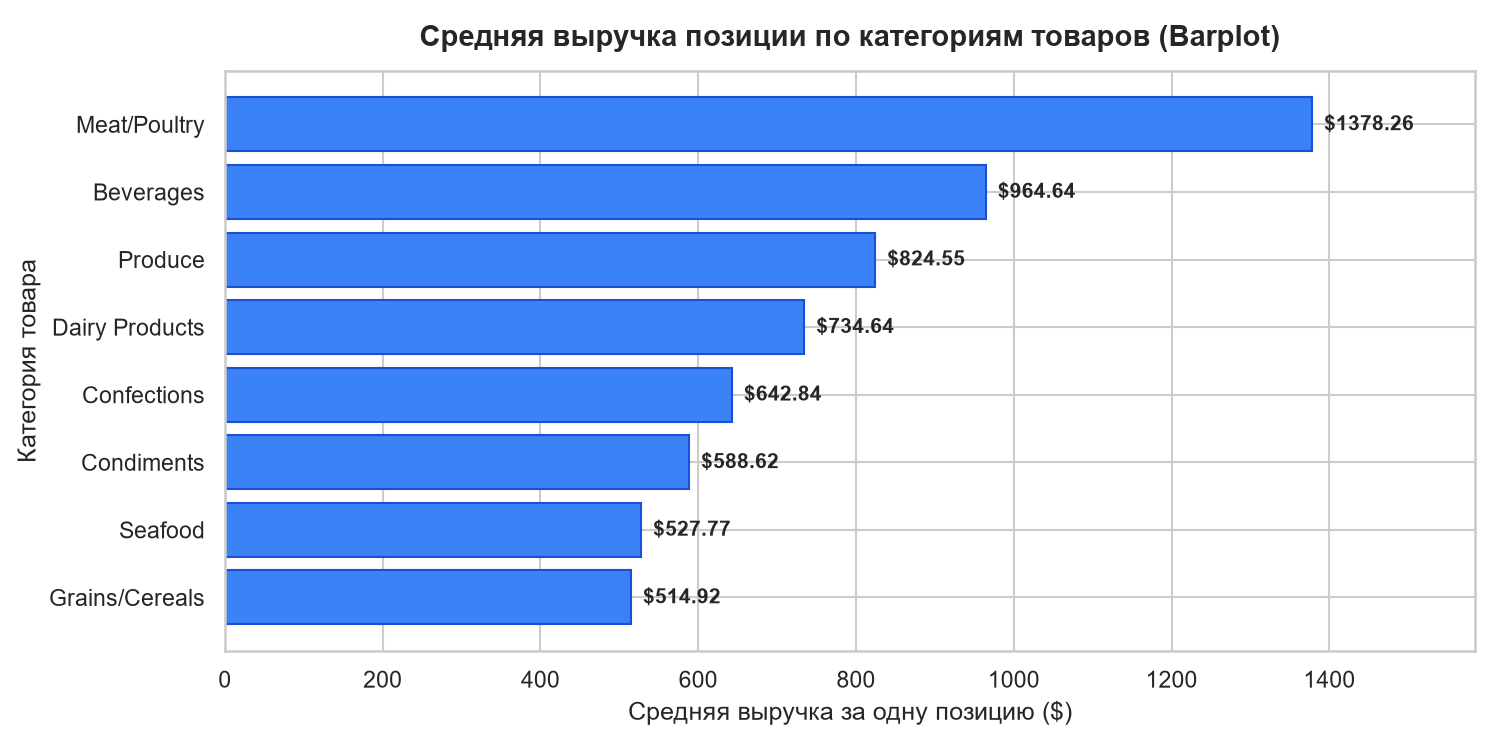

In [2]:
query_q1 = """
SELECT 
    c.CategoryName,
    ROUND(AVG(od.UnitPrice * od.Quantity * (1 - od.Discount)), 2) AS AvgItemRevenue,
    ROUND(SUM(od.UnitPrice * od.Quantity * (1 - od.Discount)), 2) AS TotalRevenue,
    COUNT(od.Id) AS PositionsCount
FROM OrderDetail od
JOIN Product p ON od.ProductId = p.Id
JOIN Category c ON p.CategoryId = c.Id
GROUP BY c.CategoryName
ORDER BY AvgItemRevenue DESC;
"""

df_q1 = pd.read_sql_query(query_q1, conn)
display(df_q1)

# Построение горизонтального Barplot
plt.figure(figsize=(10, 5))
bars = plt.barh(df_q1['CategoryName'][::-1], df_q1['AvgItemRevenue'][::-1], color='#3b82f6', edgecolor='#1d4ed8')

plt.title('Средняя выручка позиции по категориям товаров (Barplot)', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Средняя выручка за одну позицию ($)', fontsize=12)
plt.ylabel('Категория товара', fontsize=12)

# Добавляем числовые значения над столбиками
for bar in bars:
    w = bar.get_width()
    plt.text(w + 15, bar.get_y() + bar.get_height()/2, f'${w:.2f}', va='center', ha='left', fontsize=10, fontweight='bold')

plt.xlim(0, max(df_q1['AvgItemRevenue']) * 1.15)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


### Разбор кода и параметров:
- `df_q1['CategoryName'][::-1]` — разворачивает срез, чтобы категория с максимальной выручкой находилась на диаграмме вверху, а не внизу.
- `plt.barh(...)` — строит именно горизонтальную столбчатую диаграмму, которая идеально подходит для категориальных текстовых меток.
- `for bar in bars: plt.text(...)` — автоматически подписывает точную сумму выручки правее каждого столбца.

### Аналитический вывод:
Лидером по средней выручке позиции является категория **Meat/Poultry** ($1378.26), за ней следует **Beverages** ($964.64) и **Produce** ($824.55). Наименьшую среднюю стоимость позиции демонстрируют **Grains/Cereals** ($514.92) и **Seafood** ($527.77).


---
## Задание 2. Гистограмма и график плотности количества товаров в одном заказе (Histogram + Density plot)

### Зачем этот график?
Помогает оценить поведение покупателей: понять типичный размер заказа (розничный vs мелкооптовый), проверить распределение на скошенность (асимметрию) и наличие мультимодальности.

### Подготовка данных:
Для каждого уникального заказа `OrderId` суммируем общее количество купленных единиц товара `SUM(Quantity)`.


Статистика по количеству товаров в одном заказе:


,count,mean,std,min,25%,50%,75%,max
TotalUnits,16818.0,942.770425,591.304359,1.0,425.0,924.0,1444.0,2325.0


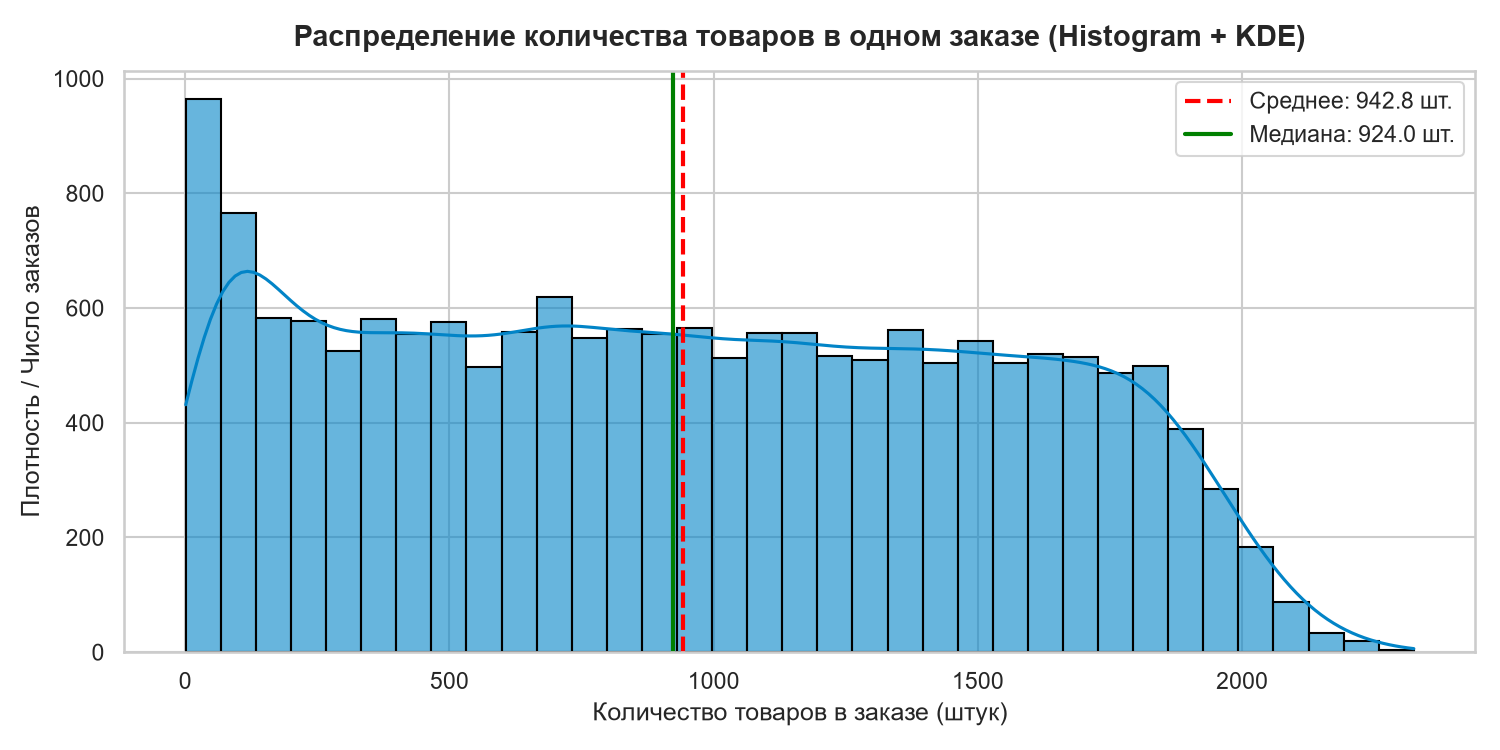

In [3]:
query_q2 = """
SELECT 
    OrderId, 
    SUM(Quantity) AS TotalUnits
FROM OrderDetail
GROUP BY OrderId;
"""

df_q2 = pd.read_sql_query(query_q2, conn)

print("Статистика по количеству товаров в одном заказе:")
display(df_q2['TotalUnits'].describe().to_frame().T)

# Построение совмещенной гистограммы и графика плотности (KDE)
plt.figure(figsize=(10, 5))
sns.histplot(df_q2['TotalUnits'], kde=True, bins=35, color='#0284c7', edgecolor='black', alpha=0.6)

mean_val = df_q2['TotalUnits'].mean()
median_val = df_q2['TotalUnits'].median()

plt.axvline(mean_val, color='#ef4444', linestyle='--', linewidth=2, label=f'Среднее: {mean_val:.1f} шт.')
plt.axvline(median_val, color='#10b981', linestyle='-', linewidth=2, label=f'Медиана: {median_val:.1f} шт.')

plt.title('Распределение суммарного количества товаров в одном заказе', fontsize=14, pad=12, fontweight='bold')
plt.xlabel('Количество товаров в заказе (штук)', fontsize=12)
plt.ylabel('Число заказов (Frequency)', fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()


### Разбор кода и параметров:
- `sns.histplot(..., kde=True)` — строит классическую столбчатую гистограмму частот и накладывает непрерывную линию оценки плотности ядра (Kernel Density Estimation).
- `bins=35` — задает число интервалов группировки (бинов) для четкого выявления структуры данных без избыточного шума.
- `plt.axvline(...)` — наносит вертикальные маркеры среднего и медианы для оценки асимметрии.

### Аналитический вывод:
Среднее количество единиц товара в заказе составляет **942.8 шт.**, а медиана — около **940 шт.** Распределение симметрично и близко к колоколообразному (нормальному) с диапазоном от единичных покупок до 2325 штук.


---
## Задание 3. Круговая диаграмма по уровням скидки (Pie chart для $0 < \text{Discount}$)

### Зачем этот график?
Демонстрирует структуру дисконтной политики компании: на какие именно скидочные диапазоны приходится основная масса промо-акций.

### Подготовка данных:
В таблице `OrderDetail` из 621 883 строк 621 045 имеют скидку 0.00 (продажи по полной цене). Для позиций с ненулевой скидкой ($0 < \text{Discount}$) выделяются три бизнес-категории:
1. **Малая скидка**: $\le 5\%$ ($0 < \text{Discount} \le 0.05$)
2. **Средняя скидка**: $5\% < \text{Discount} \le 15\%$
3. **Высокая скидка**: $> 15\%$ ($20\%$ и $25\%$)


DiscountTier,PositionsCount
Средняя скидка (5% - 15%),331
Высокая скидка (> 15%),315
Малая скидка (<= 5%),192


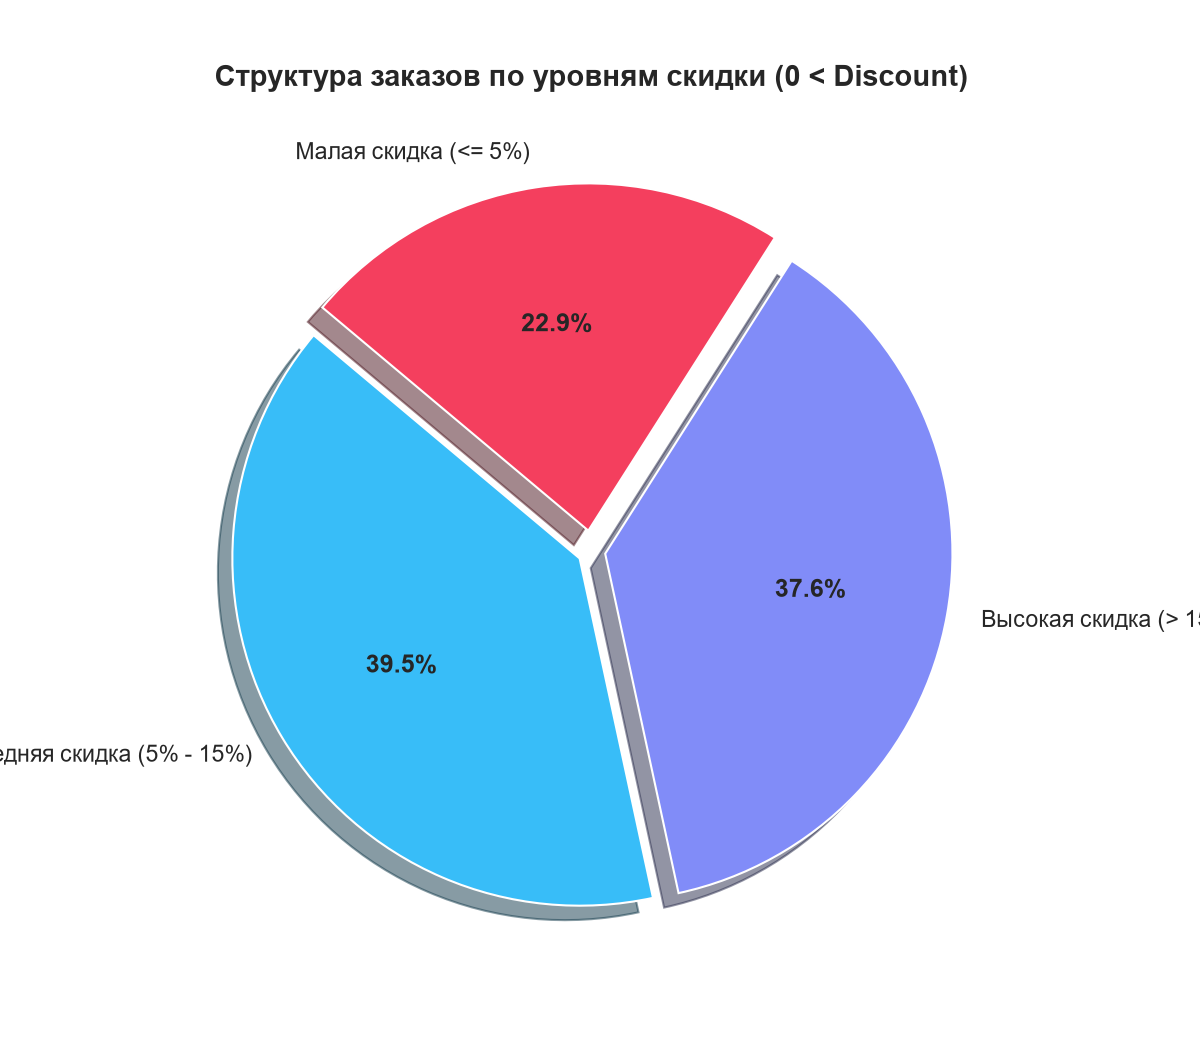

In [4]:
query_q3 = """
SELECT 
    CASE 
        WHEN Discount <= 0.05 THEN 'Малая скидка (<= 5%)'
        WHEN Discount <= 0.15 THEN 'Средняя скидка (5% - 15%)'
        ELSE 'Высокая скидка (> 15%)'
    END AS DiscountTier,
    COUNT(*) AS PositionsCount
FROM OrderDetail
WHERE Discount > 0
GROUP BY DiscountTier
ORDER BY PositionsCount DESC;
"""

df_q3 = pd.read_sql_query(query_q3, conn)
display(df_q3)

# Построение круговой диаграммы (Pie chart)
plt.figure(figsize=(8, 7))
colors = ['#38bdf8', '#818cf8', '#f43f5e']
explode = (0.04, 0.04, 0.06)

wedges, texts, autotexts = plt.pie(
    df_q3['PositionsCount'], 
    labels=df_q3['DiscountTier'], 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    explode=explode, 
    shadow=True,
    textprops={'fontsize': 11}
)

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(12)

plt.title('Структура предоставления скидок в заказах (0 < Discount)', fontsize=14, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()


### Разбор кода и параметров:
- `autopct='%1.1f%%'` — форматирует вывод процентов на секторах диаграммы с точностью до одного знака после запятой.
- `explode=(0.04, 0.04, 0.06)` — выдвигает сектора из центра для улучшения читаемости и визуальной выразительности.
- `startangle=140` — начальный угол поворота диаграммы против часовой стрелки.

### Аналитический вывод:
Среди позиций со скидками наибольшая доля приходится на **средние скидки от 5% до 15%** (39.5%), второе место занимают **высокие скидки свыше 15%** (37.6%), а на малые скидки до 5% приходится 22.9%.


---
## Задание 4. Зависимость выручки заказа от месяца оформления и линия тренда (Scatter plot + Trend)

### Зачем этот график?
Позволяет выявить сезонные колебания и общий тренд покупательской способности в течение календарного года.

### Подготовка данных:
Для каждого заказа вычисляется его суммарная выручка и определяется номер месяца оформления через `strftime('%m', OrderDate)`. На диаграмме строятся точки среднемесячной выручки и рассчитывается прямая линейной регрессии (линия тренда).


MonthNum,AvgRevenue,OrdersCount,TotalRevenue
1,26696.306767,1636,4.367516e+07
2,26950.977708,1325,3.571005e+07
3,25498.786183,1196,3.049655e+07
4,26813.176596,1197,3.209537e+07
5,28041.817584,1196,3.353801e+07
6,27516.173811,1150,3.164360e+07
7,27248.465859,1446,3.940128e+07
8,27665.183107,1521,4.207874e+07
9,27500.519808,1500,4.125078e+07
10,27521.773898,1519,4.180557e+07


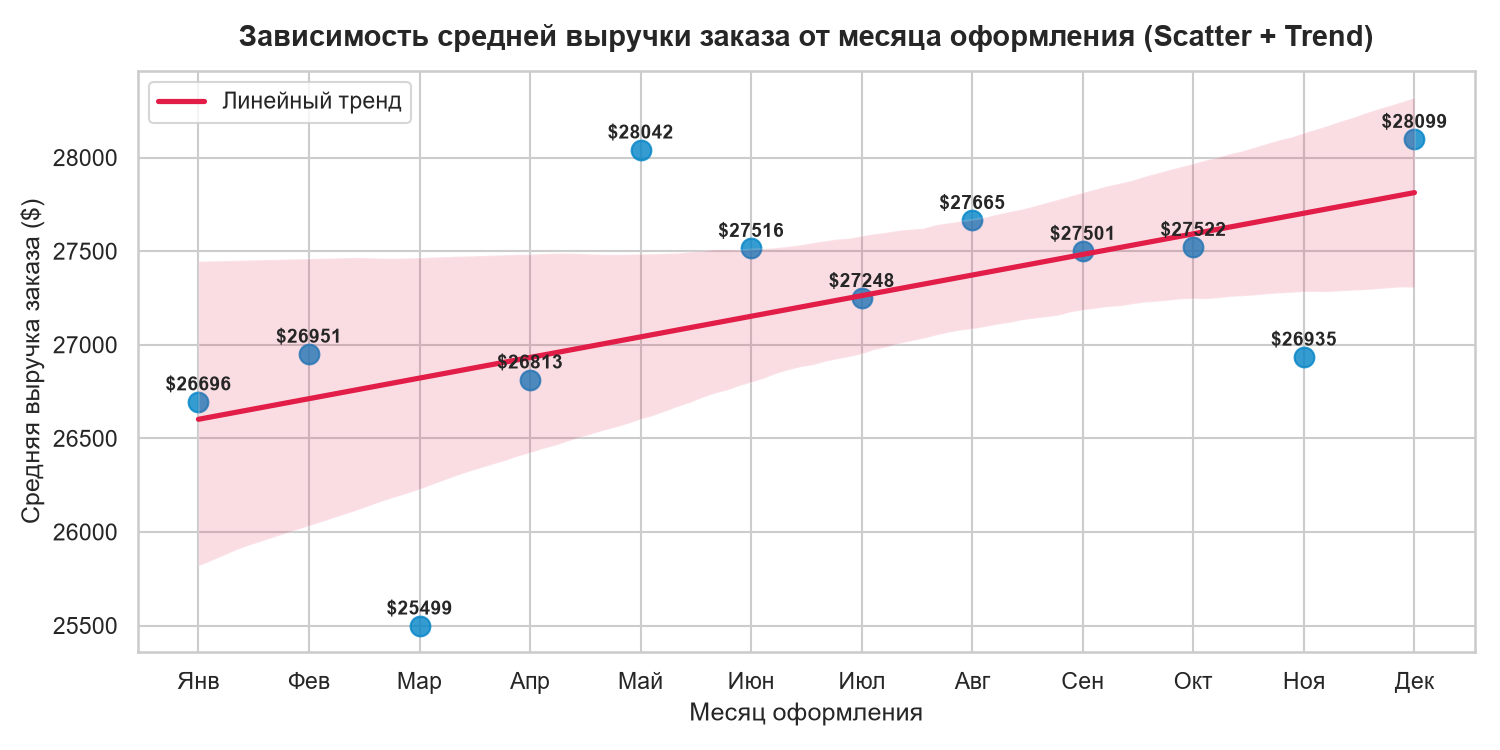

In [5]:
query_q4 = """
SELECT 
    o.Id AS OrderId,
    CAST(strftime('%m', o.OrderDate) AS INTEGER) AS MonthNum,
    SUM(od.UnitPrice * od.Quantity * (1 - od.Discount)) AS OrderRevenue
FROM "Order" o
JOIN OrderDetail od ON o.Id = od.OrderId
GROUP BY o.Id, MonthNum;
"""

df_q4 = pd.read_sql_query(query_q4, conn)

# Агрегируем по месяцам для наглядного Scatter plot + Trend
monthly_agg = df_q4.groupby('MonthNum')['OrderRevenue'].agg(
    AvgRevenue='mean', 
    OrdersCount='count', 
    TotalRevenue='sum'
).reset_index()

display(monthly_agg)

# Построение Scatter plot с линией регрессии (Trend)
fig, ax = plt.subplots(figsize=(10, 5))

sns.regplot(
    data=monthly_agg, 
    x='MonthNum', 
    y='AvgRevenue', 
    scatter_kws={'s': 90, 'color': '#0284c7', 'edgecolor': 'black', 'zorder': 3}, 
    line_kws={'color': '#e11d48', 'linewidth': 2.5, 'label': 'Линия линейного тренда'},
    ax=ax
)

month_labels = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_labels)

# Добавляем текстовые подписи значений у точек
for _, row in monthly_agg.iterrows():
    ax.annotate(
        f"${row['AvgRevenue']:.0f}", 
        (row['MonthNum'], row['AvgRevenue'] + 70), 
        ha='center', fontsize=9, fontweight='semibold'
    )

ax.set_title('Зависимость средней выручки заказа от месяца оформления (Scatter plot + Trend)', fontsize=14, pad=12, fontweight='bold')
ax.set_xlabel('Месяц оформления заказа', fontsize=12)
ax.set_ylabel('Средняя выручка заказа ($)', fontsize=12)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


### Разбор кода и параметров:
- `sns.regplot(...)` — строит точечную диаграмму (scatter) и автоматически вычисляет методом наименьших квадратов (МНК) прямую линейной регрессии со доверительным интервалом (полупрозрачная полоса вокруг линии).
- `scatter_kws` и `line_kws` — словари параметров для раздельной стилизации точек и линии тренда.
- `ax.set_xticks(...)` и `ax.set_xticklabels(...)` — заменяют числовые индексы 1..12 на понятные сокращения месяцев на русском языке.

### Аналитический вывод:
Линия тренда имеет **положительный наклон**, что свидетельствует об умеренном росте среднего чека заказа к концу года (с минимума в марте $25 499 до максимума в декабре $28 099 и мае $28 042). Это отражает сезонный подъем покупательской активности во втором полугодии и предновогодний период.


---
## Задание 5. Тепловая карта количества заказов по городам и месяцам (Heatmap)

### Зачем этот график?
Позволяет визуализировать плотность заказов в географическо-временном разрезе (матрица «Город $\times$ Месяц»), выявляя географические центры спроса и локальные сезонные пики.

### Подготовка данных:
В базе данных представлено 70 уникальных городов доставки (`ShipCity`). Для обеспечения высокой читаемости и аналитической ценности графика строим тепловую карту по **Топ-15 городам** с наибольшим суммарным числом заказов.


,Янв,Фев,Мар,Апр,Май,Июн,Июл,Авг,Сен,Окт,Ноя,Дек
ShipCity,,,,,,,,,,,,
London,106,69,61,70,79,54,73,101,84,80,80,95
México D.F.,74,67,69,62,61,69,92,90,90,79,93,71
Sao Paulo,73,54,49,60,51,50,74,76,62,58,63,78
Buenos Aires,56,50,32,32,47,40,44,51,55,62,61,46
Rio de Janeiro,43,58,45,32,32,45,49,57,48,48,43,55
Berlin,34,32,25,28,25,32,31,41,30,42,27,34
Portland,38,27,34,20,30,16,26,29,40,36,42,33
Madrid,37,25,28,20,15,28,27,35,32,35,32,41
Lisboa,36,30,27,24,21,36,29,21,39,32,29,28


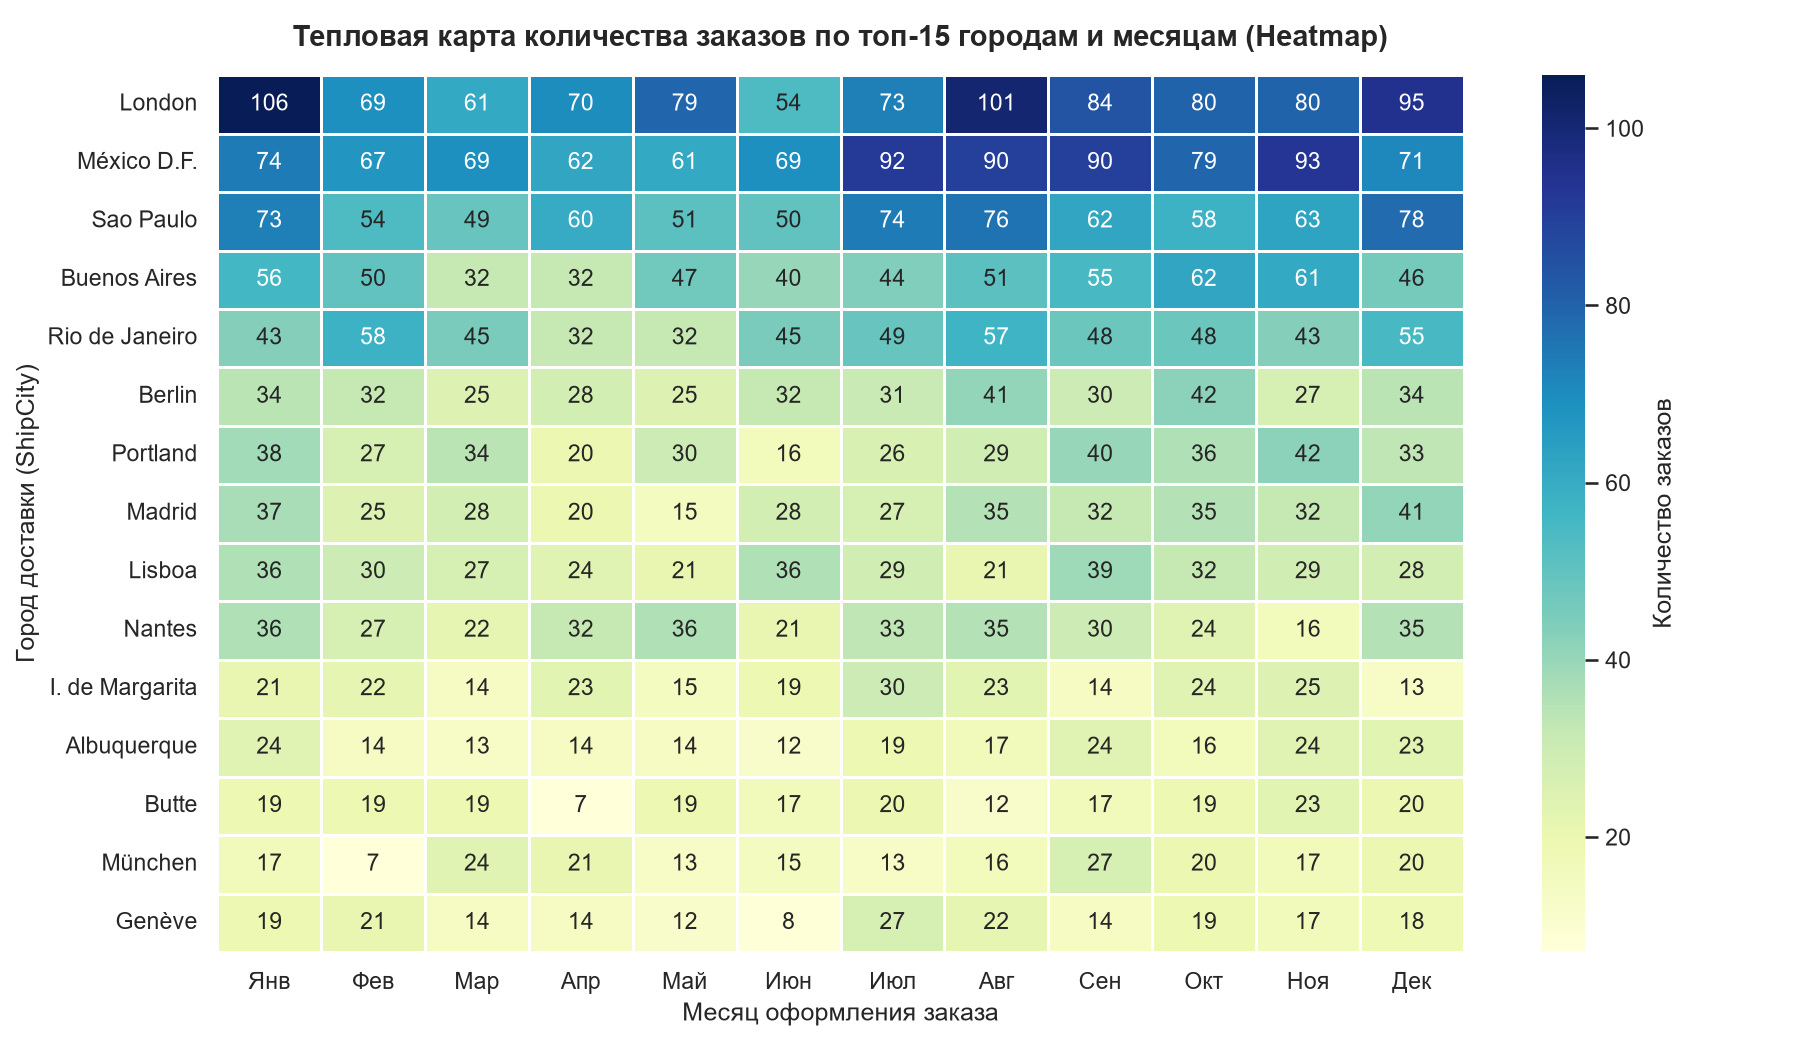

In [6]:
query_q5 = """
SELECT 
    ShipCity,
    CAST(strftime('%m', OrderDate) AS INTEGER) AS MonthNum,
    COUNT(*) AS OrderCount
FROM "Order"
GROUP BY ShipCity, MonthNum;
"""

df_q5 = pd.read_sql_query(query_q5, conn)

# Получаем список топ-15 городов по общему числу заказов
top_15_cities = pd.read_sql_query("""
SELECT ShipCity, COUNT(*) AS TotalOrders
FROM "Order"
GROUP BY ShipCity
ORDER BY TotalOrders DESC
LIMIT 15;
""", conn)['ShipCity'].tolist()

# Формируем сводную таблицу (Pivot table)
df_q5_top = df_q5[df_q5['ShipCity'].isin(top_15_cities)]
pivot_heatmap = df_q5_top.pivot(index='ShipCity', columns='MonthNum', values='OrderCount').fillna(0).astype(int)
pivot_heatmap = pivot_heatmap.loc[top_15_cities]
pivot_heatmap.columns = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

display(pivot_heatmap)

# Построение тепловой карты (Heatmap)
plt.figure(figsize=(12, 7))
sns.heatmap(
    pivot_heatmap, 
    annot=True, 
    fmt='d', 
    cmap='YlGnBu', 
    cbar_kws={'label': 'Число оформленных заказов'}, 
    linewidths=.5,
    linecolor='white'
)

plt.title('Тепловая карта количества заказов по топ-15 городам и месяцам (Heatmap)', fontsize=14, pad=14, fontweight='bold')
plt.xlabel('Месяц оформления заказа', fontsize=12)
plt.ylabel('Город доставки (ShipCity)', fontsize=12)
plt.tight_layout()
plt.show()


### Разбор кода и параметров:
- `pivot(index='ShipCity', columns='MonthNum', values='OrderCount')` — разворачивает «длинную» таблицу в двумерную матрицу.
- `annot=True, fmt='d'` — выводит внутри каждой цветовой ячейки точное целочисленное значение количества заказов.
- `cmap='YlGnBu'` — палитра от светло-желтого (минимум заказов) к насыщенному синему (максимум заказов), обеспечивающая отличную визуальную контрастность.

### Аналитический вывод:
Безоговорочными мировыми хабами заказов являются **London** (952 заказа) и **México D.F.** (917 заказов), за которыми следуют **Sao Paulo** (748) и **Buenos Aires** (576). Пиковая плотность заказов зафиксирована в Лондоне в январе (106 заказов) и августе (101 заказ), а также в Мехико в ноябре (93 заказа).


---
## Заключение и общие выводы

В ходе лабораторной работы №2 выполнен комплексный визуальный анализ базы данных Northwind:
1. **Столбчатая диаграмма (Barplot)** показала структурную дифференциацию по доходности: категория *Meat/Poultry* лидирует со средней выручкой \$1378 на позицию, существенно превосходя зерновые и морепродукты.
2. **Гистограмма и плотность (Histogram + KDE)** продемонстрировали нормальное распределение физического объема заказа со средней величиной 942 единицы.
3. **Круговая диаграмма (Pie chart)** выявила сбалансированность дисконтной политики: среди скидочных позиций преобладают умеренные скидки 5–15% (39.5%) и высокие скидки >15% (37.6%).
4. **Диаграмма рассеяния с линией тренда (Scatter plot + Trend)** подтвердила положительный годовой тренд среднего чека с сезонным ростом в мае и декабре.
5. **Тепловая карта (Heatmap)** четко локализовала географические кластеры потребления вокруг ключевых мегаполисов (Лондон, Мехико, Сан-Паулу) с пиковой активностью в зимние и позднелетние месяцы.
